In [ ]:
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import nltk

# Download required NLTK resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Load dataset
df = pd.read_csv('test.csv', encoding='latin1')
#we used latin1 for decoding as UTF-8 is appropriate here

df = df[['text', 'sentiment']]

# Basic dataset inspection
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df['sentiment'].value_counts())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (14402, 2)

Column names:
['text', 'sentiment']

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
negative    9079
neutral     3046
positive    2277
Name: count, dtype: int64

First 5 rows:


,text,sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,positive
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative


In [ ]:
# Remove rows with missing text or sentiment
df = df.dropna(subset=['text', 'sentiment']).copy()

# Reset the DataFrame index
df.reset_index(drop=True, inplace=True)

print("Dataset shape after removing missing values:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nSentiment distribution:")
print(df['sentiment'].value_counts())

Dataset shape after removing missing values: (14402, 2)

Missing values after cleaning:
text         0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
negative    9079
neutral     3046
positive    2277
Name: count, dtype: int64


In [ ]:
stop_words = set(stopwords.words('english'))

# Keep negation words because they are important for sentiment
negation_words = {'not', 'no', 'nor'}
stop_words = stop_words - negation_words


def preprocess(text):
    text = text.lower()

    tokens = word_tokenize(text)

    clean_tokens = [
        word for word in tokens
        if word.isalpha() and word not in stop_words
    ]

    return ' '.join(clean_tokens)


df['clean_text'] = df['text'].apply(preprocess)

display(df[['text', 'clean_text']].head())

,text,clean_text
0,@VirginAmerica What @dhepburn said.,virginamerica dhepburn said
1,@VirginAmerica plus you've added commercials t...,virginamerica plus added commercials experienc...
2,@VirginAmerica I didn't today... Must mean I n...,virginamerica today must mean need take anothe...
3,@VirginAmerica it's really aggressive to blast...,virginamerica really aggressive blast obnoxiou...
4,@VirginAmerica and it's a really big bad thing...,virginamerica really big bad thing


In [ ]:
# Separate input features and target labels
X = df['clean_text']
y = df['sentiment']

# First: separate the final test set
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Second: create validation set from the training portion
# 0.125 of the remaining 80% = 10% of the full dataset
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.125,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_final))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train_final.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 10080
Validation samples: 1441
Testing samples: 2881

Training class distribution:
sentiment
negative    6355
neutral     2132
positive    1593
Name: count, dtype: int64

Validation class distribution:
sentiment
negative    908
neutral     305
positive    228
Name: count, dtype: int64

Testing class distribution:
sentiment
negative    1816
neutral      609
positive     456
Name: count, dtype: int64


A common formula is:

TF(t,d)=
Count of term t in document d/Total terms in document d
	​


IDF — Inverse Document Frequency

IDF reduces the importance of words that appear in many documents.

A common smoothed formula used by scikit-learn is:

IDF(t)=log(1+n/1+df(t))+1

Where:

n = total number of documents

df(t) = number of documents containing term t

TF-IDF
TFIDF(t,d)=TF(t,d)×IDF(t)

In [ ]:
# Initialize the TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2, #A word must appear in at least 2 documents to be included in the vocabulary.
    max_df=0.95#Terms appearing in more than 95% of documents are excluded.
)

# Fit only on training data and transform it
X_train_tfidf = vectorizer.fit_transform(X_train_final)
#learns vocab and idf statistics from training text

# Transform test data using the same fitted vectorizer
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

#output give(no of doc, no of feature)

Training TF-IDF shape: (10080, 5000)
Validation TF-IDF shape: (1441, 5000)
Testing TF-IDF shape: (2881, 5000)
Vocabulary size: 5000


In [ ]:
print(type(X_train_tfidf))
#CSR- Compressed Sparse Row
#instead of adding 0 in matrix it only stores non zero value and its position
#we did sparse matrix instead of dense matrix because A sparse matrix is a matrix containing mostly zero values. In NLP, TF-IDF representations are usually sparse because each document contains only a small portion of the total vocabulary. Sparse matrices save memory by efficiently storing non-zero values and their positions

<class 'scipy.sparse._csr.csr_matrix'>


In [ ]:
label_mapping = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

y_train_encoded = y_train_final.map(label_mapping).to_numpy()
y_val_encoded = y_val.map(label_mapping).to_numpy()
y_test_encoded = y_test.map(label_mapping).to_numpy()

print("Encoded training labels:", np.unique(y_train_encoded))
print("Encoded validation labels:", np.unique(y_val_encoded))
print("Encoded testing labels:", np.unique(y_test_encoded))

Encoded training labels: [0 1 2]
Encoded validation labels: [0 1 2]
Encoded testing labels: [0 1 2]


Cell 8: Convert Sparse Matrix to Dense


*   PyTorch's standard nn.Linear layer works conveniently with dense tensors, so we'll convert the TF-IDF matrices.




In [ ]:
# Convert TF-IDF matrices from sparse format to dense NumPy arrays
X_train_dense = X_train_tfidf.toarray().astype(np.float32)
X_val_dense = X_val_tfidf.toarray().astype(np.float32)
X_test_dense = X_test_tfidf.toarray().astype(np.float32)

print("Training dense shape:", X_train_dense.shape)
print("Validation dense shape:", X_val_dense.shape)
print("Testing dense shape:", X_test_dense.shape)
print("Data type:", X_train_dense.dtype)

Training dense shape: (10080, 5000)
Validation dense shape: (1441, 5000)
Testing dense shape: (2881, 5000)
Data type: float32


Q: Why do we convert TF-IDF from sparse to dense?

We convert it to dense because our PyTorch neural network uses standard dense layers, which expect dense input tensors. However, dense conversion consumes more memory, so sparse-compatible approaches may be preferable for large datasets.

In [ ]:
# Convert dense NumPy arrays to PyTorch tensors
X_train_tensor = torch.tensor(
    X_train_dense,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_dense,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_dense,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_encoded,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_encoded,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_encoded,
    dtype=torch.long
)

print("X_train:", X_train_tensor.shape)
print("X_val:", X_val_tensor.shape)
print("X_test:", X_test_tensor.shape)

print("y_train:", y_train_tensor.shape)
print("y_val:", y_val_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([10080, 5000])
X_val: torch.Size([1441, 5000])
X_test: torch.Size([2881, 5000])
y_train: torch.Size([10080])
y_val: torch.Size([1441])
y_test: torch.Size([2881])


In [ ]:
class SentimentDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = SentimentDataset(X_train_tensor, y_train_tensor)
test_dataset = SentimentDataset(X_test_tensor, y_test_tensor)
val_dataset = SentimentDataset(X_val_tensor, y_val_tensor)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Val samples:", len(val_dataset))


Training samples: 10080
Testing samples: 2881
Val samples: 1441


"Why do we use self.X = X in a class?"

Say:

X is a parameter passed to the constructor, while self.X is an instance attribute. We store the input data in self.X so that other methods of the Dataset class, such as __len__ and __getitem__, can access it later.

Q: Why do we create a custom Dataset instead of directly giving tensors to the model?

A good answer:

A PyTorch Dataset provides a standardized interface for accessing samples and labels. It can then be used with a DataLoader to efficiently create batches, shuffle the data, and iterate through the training set.

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Number of training batches:", len(train_loader))
print("Number of testing batches:", len(test_loader))
print("Number of validation batches:", len(val_loader))

Number of training batches: 315
Number of testing batches: 91
Number of validation batches: 46


In [ ]:
X_batch, y_batch = next(iter(train_loader))

print("Batch input shape:", X_batch.shape)
print("Batch label shape:", y_batch.shape)
print("Labels:", y_batch)

Batch input shape: torch.Size([32, 5000])
Batch label shape: torch.Size([32])
Labels: tensor([2, 2, 0, 0, 1, 1, 2, 0, 1, 2, 0, 0, 0, 0, 0, 1, 2, 0, 1, 0, 0, 0, 0, 0,
        0, 2, 1, 0, 0, 0, 1, 1])


In [ ]:
class SentimentModel(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),#It introduces non-linearity, allowing the neural network to learn more complex relationships.
            nn.Dropout(0.3),#During training, dropout randomly sets approximately 30% of activations to zero. Its purpose is to reduce overfitting.
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


input_size = X_train_tensor.shape[1]
num_classes = 3

model = SentimentModel(input_size, num_classes)

print(model)

SentimentModel(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


"What is dropout and why is it used?"

Say:

Dropout is a regularization technique where a random fraction of neurons or activations are temporarily set to zero during training. It prevents the network from relying too heavily on specific neurons and can reduce overfitting. During inference, dropout is disabled.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights using training labels only
classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_encoded
)

# Convert weights to a PyTorch tensor
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
)

# Use weighted Cross-Entropy Loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# Initialize the Adam optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Class weights:", class_weights_tensor)
print("Loss function:", criterion)
print("Optimizer:", optimizer)


Class weights: tensor([0.5287, 1.5760, 2.1092])
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


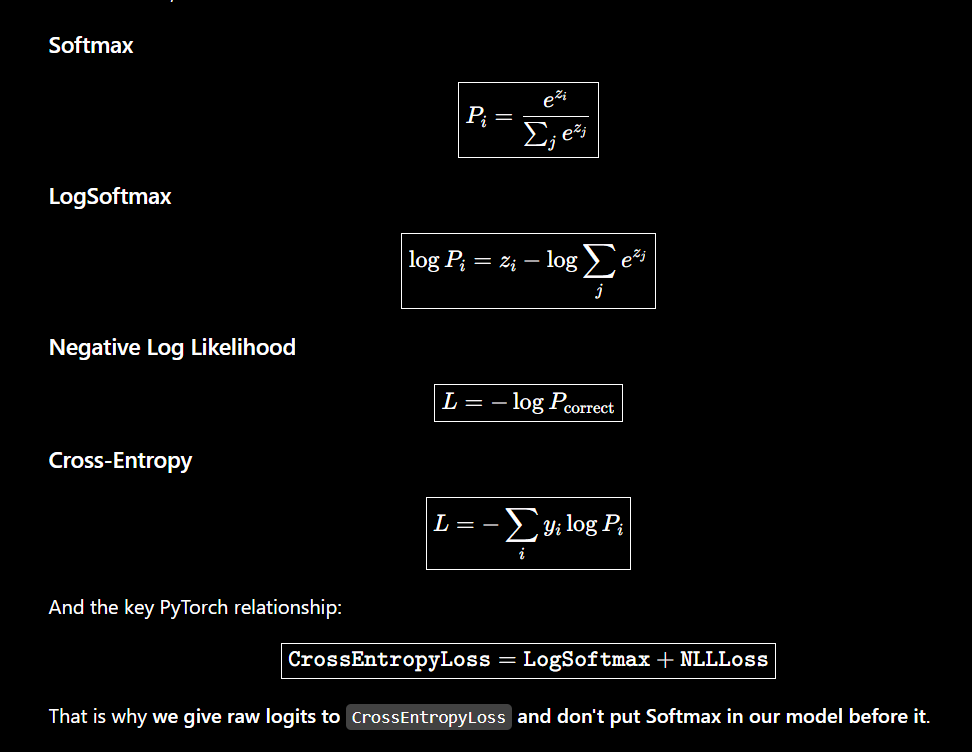

zi are logits which we get from model like [1.2,0.3,3.5]

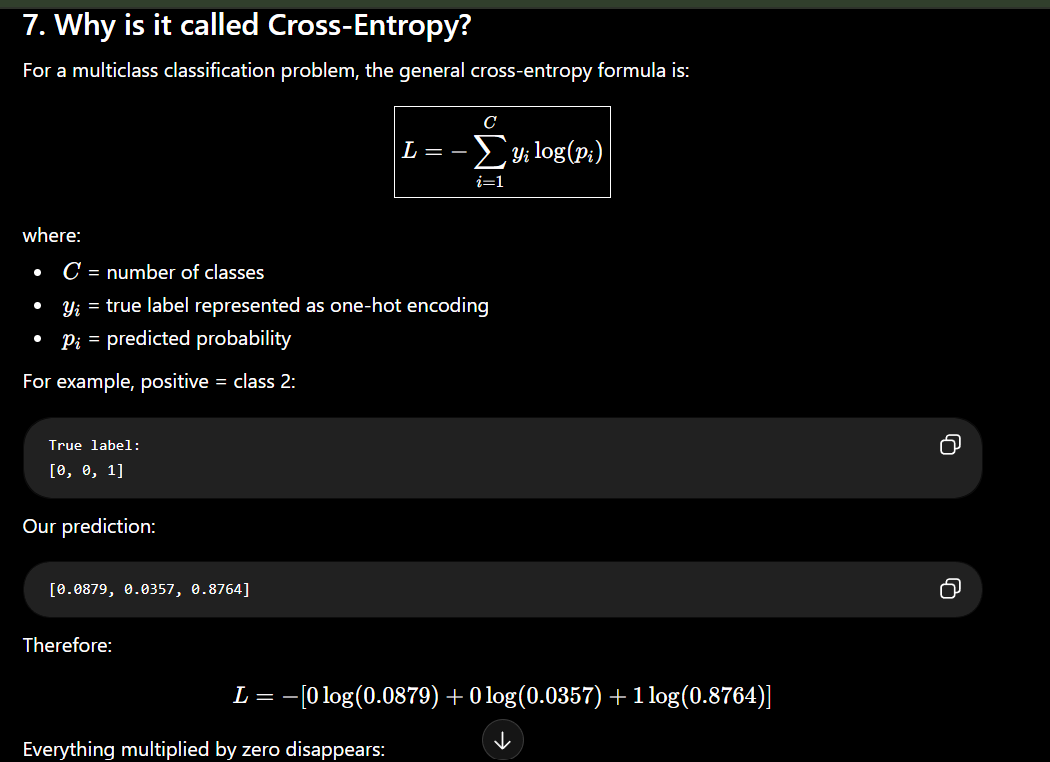

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", total_params)
#Parameters=(input features×output features)+output features

Trainable parameters: 648579


In [ ]:

# Start a fresh model for this experiment
model = SentimentModel(input_size, num_classes)

# Keep the class-weighted loss
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# Reset the optimizer for the new model
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 10

for epoch in range(num_epochs):

    # Training phase
    model.train()
    total_train_loss = 0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * y_batch.size(0)

    average_train_loss = (
        total_train_loss / len(train_loader.dataset)
    )

    # Validation phase
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            total_val_loss += loss.item() * y_batch.size(0)

    average_val_loss = (
        total_val_loss / len(val_loader.dataset)
    )

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Train Loss: {average_train_loss:.4f}, "
        f"Validation Loss: {average_val_loss:.4f}"
    )


Epoch [1/10], Train Loss: 0.8420, Validation Loss: 0.6103
Epoch [2/10], Train Loss: 0.4907, Validation Loss: 0.6010
Epoch [3/10], Train Loss: 0.3438, Validation Loss: 0.6689
Epoch [4/10], Train Loss: 0.2468, Validation Loss: 0.7927
Epoch [5/10], Train Loss: 0.1789, Validation Loss: 0.8993
Epoch [6/10], Train Loss: 0.1340, Validation Loss: 1.0629
Epoch [7/10], Train Loss: 0.0947, Validation Loss: 1.2088
Epoch [8/10], Train Loss: 0.0784, Validation Loss: 1.3929
Epoch [9/10], Train Loss: 0.0594, Validation Loss: 1.5293
Epoch [10/10], Train Loss: 0.0493, Validation Loss: 1.7196


In [ ]:
model.eval()

correct = 0
total = 0
test_loss = 0.0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)
        test_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        total += y_batch.size(0)
        correct += (predictions == y_batch).sum().item()

test_loss /= len(test_loader)
accuracy = correct / total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Loss: 1.8020
Test Accuracy: 0.7622
Test Accuracy: 76.22%


In [ ]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(y_batch.numpy())

print("Number of predictions:", len(all_predictions))
print("Number of actual labels:", len(all_labels))

Number of predictions: 2881
Number of actual labels: 2881


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[1538  199   79]
 [ 202  333   74]
 [  67   64  325]]


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    all_labels,
    all_predictions,
    target_names=['negative', 'neutral', 'positive']
)

print(report)

              precision    recall  f1-score   support

    negative       0.85      0.85      0.85      1816
     neutral       0.56      0.55      0.55       609
    positive       0.68      0.71      0.70       456

    accuracy                           0.76      2881
   macro avg       0.70      0.70      0.70      2881
weighted avg       0.76      0.76      0.76      2881



In [ ]:
misclassified = []

for text, actual, predicted in zip(
    X_test,
    all_labels,
    all_predictions
):
    if actual != predicted:
        misclassified.append({
            'text': text,
            'actual': actual,
            'predicted': predicted
        })

misclassified_df = pd.DataFrame(misclassified)

label_names = {
    0: 'negative',
    1: 'neutral',
    2: 'positive'
}

misclassified_df['actual'] = misclassified_df['actual'].map(label_names)
misclassified_df['predicted'] = misclassified_df['predicted'].map(label_names)

print("Total misclassified:", len(misclassified_df))

display(misclassified_df.head(10))

Total misclassified: 685


,text,actual,predicted
0,southwestair thanks response flight time passe...,negative,positive
1,jetblue know bar wish,positive,neutral
2,united clicked upgrade upgrade gives http,negative,neutral
3,americanair runways dfw flying late flightr to...,neutral,positive
4,usairways message want issue refund someone el...,neutral,negative
5,usairways cust svc line charlotte nc agents be...,neutral,negative
6,cc dadboner boldflavors united bringing bourbo...,positive,neutral
7,jetblue ugh always know way heart,positive,neutral
8,united thank appreciate prompt responses passe...,neutral,positive
9,united stingiest airline nobody model ptfo che...,negative,neutral


In [ ]:
error_counts = (
    misclassified_df
    .groupby(['actual', 'predicted'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
)

display(error_counts)

,actual,predicted,count
2,neutral,negative,202
0,negative,neutral,199
1,negative,positive,79
3,neutral,positive,74
4,positive,negative,67
5,positive,neutral,64


## Baseline Model Results

### TF-IDF Configuration
- `max_features = 5000`
- `ngram_range = (1, 2)`
- `min_df = 2`
- `max_df = 0.95`

### Neural Network Architecture
- Architecture: **5000 → 128 → 64 → 3**
- Hidden-layer activation: ReLU
- Dropout: 0.3
- Optimizer: Adam
- Learning rate: 0.001
- Epochs: 10
- Loss function: Cross-Entropy Loss with class weights

### Baseline Evaluation
- **Test Accuracy: 74.82%**
- **Macro F1-score: 0.68**
- Weighted F1-score: 0.75
- Test samples: 2,661
- Misclassified samples: 670

### Key Observations
- The model performs best on negative sentiment, with an F1-score of 0.85.
- Neutral sentiment is more difficult to classify, with an F1-score of 0.55.
- Positive sentiment achieves an F1-score of 0.65.
- Training loss decreases consistently, while validation loss increases after the first epoch, indicating overfitting.

### Conclusion
This model serves as the baseline for subsequent experiments. Future improvements will focus on reducing overfitting and improving neutral and positive sentiment classification while comparing results using the same train-validation-test split.

In [ ]:
print("Training samples:", len(X_train_final))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

print("\nTraining distribution:")
print(y_train_final.value_counts())

print("\nValidation distribution:")
print(y_val.value_counts())

print("\nTest distribution:")
print(y_test.value_counts())


Training samples: 10080
Validation samples: 1441
Test samples: 2881

Training distribution:
sentiment
negative    6355
neutral     2132
positive    1593
Name: count, dtype: int64

Validation distribution:
sentiment
negative    908
neutral     305
positive    228
Name: count, dtype: int64

Test distribution:
sentiment
negative    1816
neutral      609
positive     456
Name: count, dtype: int64


In [ ]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95
)

X_train_tfidf = vectorizer.fit_transform(X_train_final)

X_val_tfidf = vectorizer.transform(X_val)

X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Validation TF-IDF shape:", X_val_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))

Training TF-IDF shape: (10080, 5000)
Validation TF-IDF shape: (1441, 5000)
Testing TF-IDF shape: (2881, 5000)
Vocabulary size: 5000


In [ ]:
label_mapping = {
    'negative': 0,
    'neutral': 1,
    'positive': 2
}

y_train_encoded = y_train_final.map(label_mapping).to_numpy()
y_val_encoded = y_val.map(label_mapping).to_numpy()
y_test_encoded = y_test.map(label_mapping).to_numpy()

print("Training labels:", np.unique(y_train_encoded))
print("Validation labels:", np.unique(y_val_encoded))
print("Testing labels:", np.unique(y_test_encoded))

Training labels: [0 1 2]
Validation labels: [0 1 2]
Testing labels: [0 1 2]


In [ ]:
X_train_dense = X_train_tfidf.toarray().astype(np.float32)
X_val_dense = X_val_tfidf.toarray().astype(np.float32)
X_test_dense = X_test_tfidf.toarray().astype(np.float32)

X_train_tensor = torch.tensor(X_train_dense, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_dense, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_dense, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_encoded, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_encoded, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_encoded, dtype=torch.long)

print("X_train:", X_train_tensor.shape)
print("X_val:", X_val_tensor.shape)
print("X_test:", X_test_tensor.shape)

print("y_train:", y_train_tensor.shape)
print("y_val:", y_val_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([10080, 5000])
X_val: torch.Size([1441, 5000])
X_test: torch.Size([2881, 5000])
y_train: torch.Size([10080])
y_val: torch.Size([1441])
y_test: torch.Size([2881])


In [ ]:
train_dataset = SentimentDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset = SentimentDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = SentimentDataset(
    X_test_tensor,
    y_test_tensor
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Training samples: 10080
Validation samples: 1441
Testing samples: 2881


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 315
Validation batches: 46
Testing batches: 91


In [ ]:
model = SentimentModel(
    input_size=X_train_tensor.shape[1],
    num_classes=3
)

print(model)

SentimentModel(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [ ]:

from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1, 2])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_encoded
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
)

criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Class weights:", class_weights_tensor)
print("Loss function:", criterion)
print("Optimizer:", optimizer)


Class weights: tensor([0.5287, 1.5760, 2.1092])
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:

num_epochs = 10
best_val_loss = float("inf")
best_model_state = None

for epoch in range(num_epochs):

    # Training
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)
            val_total += y_batch.size(0)
            val_correct += (predictions == y_batch).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = val_correct / val_total

    # Save the model with the lowest validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {
            key: value.detach().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

print(f"\nBest validation loss: {best_val_loss:.4f}")


Epoch [1/10] | Train Loss: 0.8310 | Val Loss: 0.5973 | Val Accuracy: 0.7710
Epoch [2/10] | Train Loss: 0.4759 | Val Loss: 0.5956 | Val Accuracy: 0.7724
Epoch [3/10] | Train Loss: 0.3319 | Val Loss: 0.6575 | Val Accuracy: 0.7772
Epoch [4/10] | Train Loss: 0.2361 | Val Loss: 0.7554 | Val Accuracy: 0.7835
Epoch [5/10] | Train Loss: 0.1650 | Val Loss: 0.9183 | Val Accuracy: 0.7835
Epoch [6/10] | Train Loss: 0.1216 | Val Loss: 1.0448 | Val Accuracy: 0.7703
Epoch [7/10] | Train Loss: 0.0864 | Val Loss: 1.2187 | Val Accuracy: 0.7668
Epoch [8/10] | Train Loss: 0.0672 | Val Loss: 1.3948 | Val Accuracy: 0.7710
Epoch [9/10] | Train Loss: 0.0562 | Val Loss: 1.5207 | Val Accuracy: 0.7731
Epoch [10/10] | Train Loss: 0.0486 | Val Loss: 1.5956 | Val Accuracy: 0.7627

Best validation loss: 0.5956


In [ ]:
model = SentimentModel(
    input_size=X_train_tensor.shape[1],
    num_classes=3
)

# Change dropout from 0.3 to 0.5
model.network[2].p = 0.5
model.network[5].p = 0.5

print(model)

SentimentModel(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Learning rate:", optimizer.param_groups[0]['lr'])

Loss function: CrossEntropyLoss()
Learning rate: 0.001


In [ ]:
num_epochs = 10

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            val_loss += loss.item()

            predictions = torch.argmax(outputs, dim=1)

            val_total += y_batch.size(0)
            val_correct += (predictions == y_batch).sum().item()

    val_loss /= len(val_loader)
    val_accuracy = val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/10] | Train Loss: 0.7609 | Val Loss: 0.6056 | Val Accuracy: 0.7759
Epoch [2/10] | Train Loss: 0.5201 | Val Loss: 0.5254 | Val Accuracy: 0.7897
Epoch [3/10] | Train Loss: 0.3915 | Val Loss: 0.5151 | Val Accuracy: 0.7988
Epoch [4/10] | Train Loss: 0.3166 | Val Loss: 0.5326 | Val Accuracy: 0.8036
Epoch [5/10] | Train Loss: 0.2526 | Val Loss: 0.6243 | Val Accuracy: 0.7890
Epoch [6/10] | Train Loss: 0.2029 | Val Loss: 0.6746 | Val Accuracy: 0.7904
Epoch [7/10] | Train Loss: 0.1660 | Val Loss: 0.7269 | Val Accuracy: 0.7870
Epoch [8/10] | Train Loss: 0.1251 | Val Loss: 0.8280 | Val Accuracy: 0.7849
Epoch [9/10] | Train Loss: 0.1009 | Val Loss: 0.9002 | Val Accuracy: 0.7759
Epoch [10/10] | Train Loss: 0.0845 | Val Loss: 0.9934 | Val Accuracy: 0.7786


In [ ]:
model = SentimentModel(
    input_size=X_train_tensor.shape[1],
    num_classes=3
)

# Increase dropout from 0.3 to 0.5
model.network[2].p = 0.5
model.network[5].p = 0.5

# Verify the updated architecture
print(model)

SentimentModel(
  (network): Sequential(
    (0): Linear(in_features=5000, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.5, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.5, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


In [ ]:
import copy

# Reset optimizer for the fresh model with dropout = 0.5
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 20
patience = 3

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

for epoch in range(num_epochs):

    # Training
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * y_batch.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            val_loss += loss.item() * y_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)
            val_total += y_batch.size(0)
            val_correct += (predictions == y_batch).sum().item()

    val_loss /= len(val_loader.dataset)
    val_accuracy = val_correct / val_total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    # Early stopping and best-model checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0

        print("  → Validation loss improved. Model saved.")

    else:
        epochs_without_improvement += 1

        print(
            f"  → No improvement "
            f"({epochs_without_improvement}/{patience})"
        )

        if epochs_without_improvement >= patience:
            print("  → Early stopping triggered.")
            break

# Restore the best checkpoint
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print(f"\nBest validation loss: {best_val_loss:.4f}")

Epoch [1/20] | Train Loss: 0.7593 | Val Loss: 0.5960 | Val Accuracy: 0.7731
  → Validation loss improved. Model saved.
Epoch [2/20] | Train Loss: 0.5011 | Val Loss: 0.5129 | Val Accuracy: 0.8022
  → Validation loss improved. Model saved.
Epoch [3/20] | Train Loss: 0.3793 | Val Loss: 0.5089 | Val Accuracy: 0.7994
  → Validation loss improved. Model saved.
Epoch [4/20] | Train Loss: 0.3049 | Val Loss: 0.5564 | Val Accuracy: 0.7988
  → No improvement (1/3)
Epoch [5/20] | Train Loss: 0.2432 | Val Loss: 0.6180 | Val Accuracy: 0.7918
  → No improvement (2/3)
Epoch [6/20] | Train Loss: 0.2013 | Val Loss: 0.6939 | Val Accuracy: 0.7932
  → No improvement (3/3)
  → Early stopping triggered.

Best validation loss: 0.5089


In [ ]:
model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        loss = criterion(outputs, y_batch)

        test_loss += loss.item() * y_batch.size(0)

        predictions = torch.argmax(outputs, dim=1)

        test_total += y_batch.size(0)
        test_correct += (predictions == y_batch).sum().item()

test_loss /= test_total
test_accuracy = test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Loss: 0.5432
Test Accuracy: 0.7848
Test Accuracy: 78.48%


In [ ]:
from sklearn.metrics import classification_report

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(y_batch.numpy())

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=['negative', 'neutral', 'positive']
    )
)

              precision    recall  f1-score   support

    negative       0.86      0.87      0.86      1816
     neutral       0.60      0.57      0.58       609
    positive       0.73      0.72      0.73       456

    accuracy                           0.78      2881
   macro avg       0.73      0.72      0.72      2881
weighted avg       0.78      0.78      0.78      2881



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Final Confusion Matrix:")
print(cm)

Final Confusion Matrix:
[[1586  172   58]
 [ 201  347   61]
 [  65   63  328]]


## Conclusion: TF-IDF + PyTorch Neural Network

In this experiment, I developed a sentiment classification model using TF-IDF features and a PyTorch neural network to classify tweets into three categories: negative, neutral, and positive.

I experimented with different configurations, including class-weighted versus unweighted cross-entropy loss, dropout rates of 0.3 and 0.5, and different training procedures.

The initial experiment using class-weighted loss and a dropout rate of 0.3 achieved **76.22% test accuracy**, with a macro F1-score of 0.70. The final selected configuration used a dropout rate of 0.5, an unweighted cross-entropy loss, and early stopping based on validation loss. It achieved **78.48% test accuracy**, a macro F1-score of 0.72, and a weighted F1-score of 0.78.

The classification report showed that the model performed best on negative tweets, achieving an F1-score of 0.86. Positive tweets achieved an F1-score of 0.73, while neutral tweets achieved 0.58. This indicates that distinguishing neutral sentiment from negative or positive sentiment remains a challenge.

Overall, these experiments demonstrate that hyperparameter selection and training control can affect model performance. Further improvements could include better handling of class imbalance, more effective text preprocessing, and comparison with pretrained transformer models such as DistilBERT.
